# Classificatore di immagini: Marte o un altro gatto?

L'obiettivo è addestrare una rete neurale che, data una foto di un gatto, dica se è **Marte** oppure **un altro gatto**.

**Dataset**: la cartella `drive` (scaricata in locale, quindi senza `drive.mount`) contiene una sottocartella per classe:

| Cartella | Classe | Etichetta | Immagini |
|---|---|---|---|
| `00_othercat` | altro gatto | 0 | 2111 |
| `01_marte` | Marte | 1 | 96 |

**Percorso del notebook**

1. Import e percorso dei dati
2. La rete: CatClassifier
3. Dataset e trasformazioni
4. Divisione train / validation
5. Addestramento di CatClassifier
6. Valutazione sul validation set
7. Transfer learning con ResNet18
8. Valutazione della ResNet e confronto

In [1]:
%pip install torch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Come si addestra una rete neurale

L'addestramento ripete, per ogni batch di immagini, quattro passi:

1. **Forward pass**: la rete riceve le immagini e produce una previsione.
2. **Loss function**: misura quanto la previsione si discosta dalla realtà (l'etichetta corretta).
3. **Backpropagation**: a partire dalla loss si calcolano i **gradienti**, che indicano quanto ogni parametro della rete ha contribuito all'errore.
4. **Ottimizzatore**: usa i gradienti per aggiornare i parametri in modo da ridurre l'errore.

Un passaggio completo su tutte le immagini di training si chiama **epoca**.

## 1. Import e percorso dei dati

Importiamo PyTorch (`torch`, `nn` per i layer, `F` per le funzioni di attivazione), `torchvision` (dataset, modelli pre-addestrati e trasformazioni delle immagini) e PIL per aprire le foto.

`torch.manual_seed(42)` fissa il generatore di numeri casuali: inizializzazione dei pesi, split e mescolamento dei batch saranno gli stessi a ogni esecuzione, così i risultati sono riproducibili.

`data_dir` punta alla cartella `drive` locale, relativa alla cartella del notebook.

In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torch
from PIL import Image

torch.manual_seed(42) #Imposto il seed per la riproducibilità dei risultati

In [3]:
from pathlib import Path
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

data_dir = Path("../drive") #Cartella scaricata in local

## 2. La rete: CatClassifier

Una rete convoluzionale (CNN) semplice, con due blocchi *convoluzione → ReLU → max pooling* seguiti da due layer completamente connessi:

| Layer | Cosa fa | Forma dell'output |
|---|---|---|
| input | immagine RGB | 3 × 224 × 224 |
| `conv1` + ReLU | 16 filtri 3×3 (il padding mantiene la dimensione) | 16 × 224 × 224 |
| `pool` | max pooling 2×2, dimezza larghezza e altezza | 16 × 112 × 112 |
| `conv2` + ReLU | 8 filtri 3×3 | 8 × 112 × 112 |
| `pool` | max pooling 2×2 | 8 × 56 × 56 |
| `flatten` | "srotola" in un vettore | 25088 |
| `fc1` + ReLU | layer denso | 32 |
| `fc2` | un punteggio (**logit**) per classe | 2 |

L'output non è una probabilità ma due punteggi: la classe prevista è quella con il punteggio più alto. In totale la rete ha circa 800 mila parametri, quasi tutti in `fc1`.

In [16]:
class CatClassifier(nn.Module): 
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1) #Aggiungo il padding per mantenere le dimensioni dell'immagine e non perdere pixel
        self.conv2 = nn.Conv2d(16, 8, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(8 * 56 * 56, 32) #Assumendo che l'immagine di input sia 224x224, dopo due convoluzioni e due pooling, le dimensioni diventano 56x56
        self.fc2 = nn.Linear(32, 2) #Output layer per classificazione binaria (gatto A o altro gatto)

    def forward(self, x): #Definisce il percorso dei dati attraverso la rete (deve essere indentato DENTRO la classe)
        out = self.pool(F.relu(self.conv1(x)))
        out = self.pool(F.relu(self.conv2(out)))
        out = self.flatten(out)
        out = F.relu(self.fc1(out))
        out = self.fc2(out)
        return out



## 3. Dataset e trasformazioni

Ogni immagine, prima di entrare nella rete, passa per `transform`:
- `Resize((224, 224))`: tutte le foto alla stessa dimensione, quella per cui è stata progettata la rete;
- `ToTensor()`: da immagine PIL a tensore `3 × 224 × 224` con valori tra 0 e 1.

`ImageFolder` costruisce il dataset leggendo le sottocartelle di `drive`: **il nome della cartella è l'etichetta**. Le cartelle vengono ordinate alfabeticamente, per questo i prefissi `00_` e `01_` fissano `00_othercat → 0` e `01_marte → 1`.

La cella successiva mostra 5 foto a caso per ciascuna classe, già trasformate come le vede la rete.

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)), #Ridimensiono l'immagine a 224
    transforms.ToTensor() #Converto l'immagine in un tensore
])


dataset = datasets.ImageFolder(data_dir, transform=transform) #Ogni sottocartella è una classe: 00_othercat -> 0, 01_marte -> 1
loader = DataLoader(dataset, batch_size=32, shuffle=True)

print(dataset.class_to_idx)
print(len(dataset), "immagini")

{'00_othercat': 0, '01_marte': 1}
2207 immagini


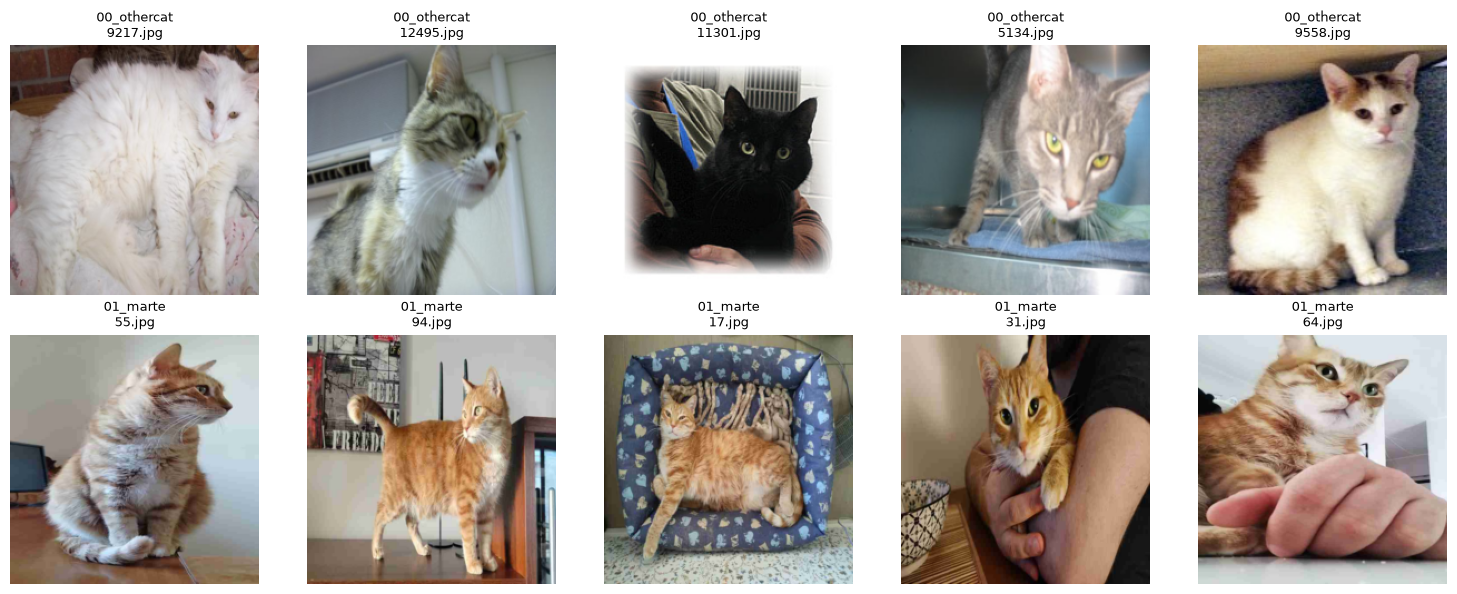

In [18]:
import random
import matplotlib.pyplot as plt

n_foto = 5 #Numero di foto da mostrare per ogni classe
fig, axes = plt.subplots(len(dataset.classes), n_foto, figsize=(3 * n_foto, 3 * len(dataset.classes)))

for idx, nome_classe in enumerate(dataset.classes):
    percorsi = [path for path, label in dataset.samples if label == idx] #Prendo tutte le foto di questa classe
    for ax, path in zip(axes[idx], random.sample(percorsi, n_foto)): #Scelgo n_foto a caso
        img = transform(Image.open(path).convert("RGB")) #Applico lo stesso transform usato dalla rete
        ax.imshow(img.permute(1, 2, 0)) #Il tensore è (C, H, W), matplotlib vuole (H, W, C)
        ax.set_title(f"{nome_classe}\n{Path(path).name}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Divisione train / validation

Dividiamo le immagini in due insiemi:
- **training (80%, 1765 immagini)**: quelle usate per aggiornare i pesi;
- **validation (20%, 442 immagini)**: immagini che la rete non vede mai durante l'addestramento, usate solo per misurare quanto sa **generalizzare**.

`val_size` è calcolato per differenza (`len(dataset) - train_size`) perché `random_split` richiede che la somma sia esattamente uguale al numero di immagini.

I `DataLoader` servono le immagini a gruppi (**batch**) di 32. Il training è mescolato a ogni epoca (`shuffle=True`), il validation no: l'ordine non cambia il risultato della valutazione.

Nota: lo split è casuale e non stratificato, quindi la proporzione di foto di Marte nel validation set (21 su 442) è affidata al caso.

In [5]:
train_size = int(0.8 * len(dataset)) #80% per il training
val_size = len(dataset) - train_size #Il resto (~20%) per il validation: così la somma è esattamente len(dataset)
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) #Ad ogni epoca le immagini vengono mischiate
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False) #Non mischiamo le immagini di validazione

## 5. Addestramento di CatClassifier

- **Loss**: `CrossEntropyLoss`, la scelta standard per la classificazione. Riceve i logit della rete e l'etichetta corretta.
- **Ottimizzatore**: `Adam` con learning rate 0.0001, cioè quanto grandi sono i passi di aggiornamento dei pesi.
- **Epoche**: 15 passaggi completi sul training set.

Dentro il ciclo ritroviamo i 4 passi visti all'inizio: forward pass (`model(images)`), loss, backpropagation (`loss.backward()`) e aggiornamento (`optimizer.step()`). `optimizer.zero_grad()` azzera i gradienti del batch precedente, che altrimenti si sommerebbero. A ogni epoca viene stampata la loss media.

In [20]:
model = CatClassifier() #Rete Neurale Convoluzionale definita sopra

loss_fn = nn.CrossEntropyLoss() #Funzione di perdita per classificazione multi-classe
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001) #Ottimizzatore Adam con learning rate 0.0001

model.train() #Setto il modello in modalità training
for epoch in range(15): #Numero di epoche
    running_loss = 0.0
    for images, labels in train_loader: 
        optimizer.zero_grad() #Azzero i gradienti
        outputs = model(images) #Passo le immagini attraverso la rete
        loss = loss_fn(outputs, labels) #Calcolo la perdita
        loss.backward() #Calcolo il gradiente
        optimizer.step() #Aggiorno i pesi
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader) #Calcolo la perdita media per epoca
    print(f"Epoch: {epoch} - Loss: {avg_loss:.4f}") #Stampa la perdita finale dell'ultima epoca

Epoch: 0 - Loss: 0.2602
Epoch: 1 - Loss: 0.1885
Epoch: 2 - Loss: 0.1722
Epoch: 3 - Loss: 0.1730
Epoch: 4 - Loss: 0.1593
Epoch: 5 - Loss: 0.1526
Epoch: 6 - Loss: 0.1494
Epoch: 7 - Loss: 0.1457
Epoch: 8 - Loss: 0.1428
Epoch: 9 - Loss: 0.1339
Epoch: 10 - Loss: 0.1311
Epoch: 11 - Loss: 0.1236
Epoch: 12 - Loss: 0.1220
Epoch: 13 - Loss: 0.1143
Epoch: 14 - Loss: 0.1056


La loss media scende da circa 0.26 a 0.11: la rete sta imparando qualcosa **sui dati di training**.
Non conviene però concentrarsi solo sul ridurre questo valore: aggiungendo epoche la rete finirebbe per memorizzare le immagini di training (**overfitting**) invece di imparare a generalizzare.
Per capire davvero come si comporta servono metriche calcolate su immagini che la rete **non ha mai visto** (il validation set), come vediamo nella sezione 6.

### Prova su una singola immagine

Prima di una valutazione completa, proviamo la rete su una foto esterna al dataset (`marte_sofa.jpg`):
- `model.eval()` mette la rete in modalità valutazione;
- `unsqueeze(0)` aggiunge la dimensione del batch, perché la rete si aspetta sempre un gruppo di immagini (qui un gruppo da 1);
- `torch.max(logits, 1)` restituisce l'indice della classe con il punteggio più alto: `1` = Marte, `0` = altro gatto.

Una singola previsione corretta però non dimostra nulla: per giudicare la rete serve il validation set.

In [23]:
model.eval() #Setto il modello in modalità evaluation
image = Image.open("marte_sofa.jpg").convert("RGB") #Apro l'immagine (il ridimensionamento lo fa già transform)
image_tensor = transform(image).unsqueeze(0) #Aggiungo una dimensione batch
model(image_tensor) #Passo l'immagine attraverso il modello per ottenere le predizioni
logits = model(image_tensor) #Ottengo i logits (output non normalizzato)
_, pred = torch.max(logits, 1) #Prendo l'indice della classe con il valore più alto
print(pred)

tensor([1])


## 6. Valutazione sul validation set

Il problema ha due classi. Prendiamo **Marte come classe positiva** (etichetta 1) e gli altri gatti come **classe negativa** (etichetta 0). Ogni previsione ricade in uno di quattro casi:

| | Previsto Marte | Previsto altro gatto |
|---|---|---|
| **È davvero Marte** | TP (vero positivo) | FN (falso negativo) |
| **È un altro gatto** | FP (falso positivo) | TN (vero negativo) |

Questa tabella 2x2 è la **matrice di confusione**. Da qui ricaviamo tre metriche:

- **Accuratezza** = (TP + TN) / totale: quante previsioni sono giuste in generale.
- **Precisione** = TP / (TP + FP): quando la rete dice "Marte", quante volte ha ragione.
- **Sensibilità (recall)** = TP / (TP + FN): di tutte le foto di Marte, quante ne riconosce.

La cella seguente calcola le metriche sul validation set e mostra i **falsi positivi**, cioè gli altri gatti scambiati per Marte. La modalità `model.eval()` e il blocco `torch.no_grad()` servono perché qui non stiamo addestrando: niente aggiornamento dei pesi e niente calcolo dei gradienti.

Accuratezza: 94.57%
Precisione: 20.00%
Recall: 4.76%
False Positives: 4


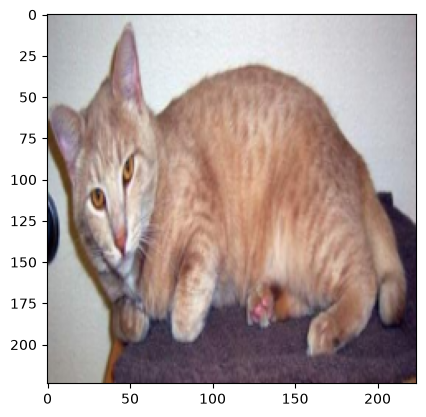

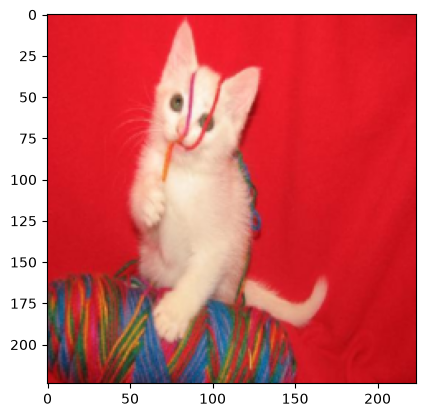

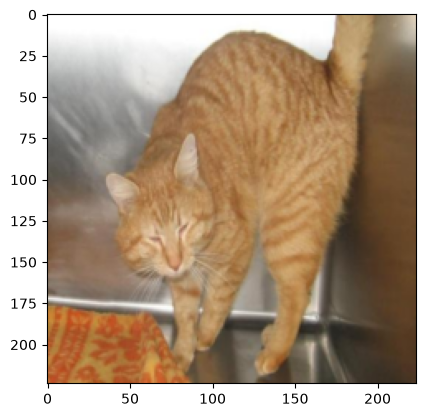

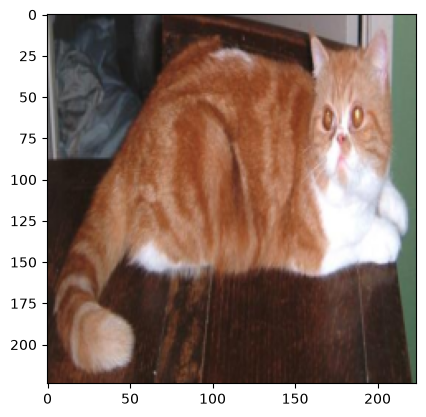

In [30]:
from matplotlib import pyplot
from sklearn.metrics import classification_report, confusion_matrix

val_preds, val_labels = [], [] #Liste per salvare le predizioni e le etichette reali
false_positives = [] #Lista per salvare le immagini classificate erroneamente come "marte"

model.eval() #Setto il modello in modalità evaluation
with torch.no_grad():
    for images, labels in val_loader: #Itero sul validation set
        logits = model(images) #Passo le immagini attraverso il modello
        _, preds = torch.max(logits, 1) #Prendo l'indice della classe con il valore più alto
        val_preds.extend(preds.tolist()) #Aggiungo le predizioni del batch alla lista (preds, non pred della cella precedente)
        val_labels.extend(labels.tolist()) #Aggiungo le etichette reali alla lista  
        false_positives.extend(images[(preds == 1) & (labels == 0)]) #Aggiungo le immagini classificate erroneamente come "marte" alla lista

report_dict = classification_report(val_labels, val_preds, output_dict=True) #Stampa il report di classificazione con precision, recall e f1-score
print(f"Accuratezza: {report_dict['accuracy']:.2%}") #Stampa l'accuratezza del modello
print(f"Precisione: {report_dict['1']['precision']:.2%}") #Stampa la precisione del modello per la classe "marte"
print(f"Recall: {report_dict['1']['recall']:.2%}") #Stampa il recall del modello per la classe "marte"

print(f"False Positives: {len(false_positives)}") #Stampa il numero di falsi positivi
for image in false_positives:
    pyplot.imshow(image.permute(1, 2, 0)) #Il tensore è (C, H, W), matplotlib vuole (H, W, C)
    pyplot.show()


### Cosa ci dicono i risultati

Sul validation set CatClassifier ottiene **accuratezza 94.57%**, ma **precisione 20%** e **recall 4.76%**: delle 21 foto di Marte nel validation set ne riconosce solo una.

L'accuratezza qui è ingannevole. Il dataset è **sbilanciato** (2111 immagini di altri gatti contro 96 di Marte): una rete che rispondesse sempre "altro gatto" otterrebbe il 95.25%, cioè più della nostra. Le metriche che contano sono precisione e recall sulla classe Marte, e sono basse.

A cosa è dovuto? La struttura della rete, seppur semplice, è adeguata allo scopo; potremmo provare più o meno epoche o un learning rate diverso, ma il vero problema principale è il dataset. Le strade possibili sono:

- **data augmentation**: generare varianti delle foto di Marte (rotazioni, ritagli, variazioni di luce) per arricchire la classe minoritaria;
- **pesare le classi nella loss** (`CrossEntropyLoss(weight=...)`), così sbagliare su Marte costa di più;
- **transfer learning**, che proviamo nella prossima sezione.

## 7. Transfer learning con ResNet18

### L'idea in parole semplici

Insegnare da zero a una rete a "vedere" richiede moltissime foto, e noi di Marte ne abbiamo solo 96. Il **transfer learning** aggira il problema: invece di partire da una rete che non sa nulla, prendiamo una rete che **ha già imparato a guardare le immagini** e le insegniamo solo l'ultima cosa che ci serve, cioè distinguere Marte dagli altri gatti.

È come affidare il lavoro a un fotografo esperto invece che a qualcuno che non ha mai visto una foto: sa già riconoscere forme, colori, pelo, occhi, orecchie. Dobbiamo solo mostrargli com'è fatto Marte.

### Chi è ResNet18

ResNet18 è una rete convoluzionale come la nostra CatClassifier, ma molto più grande: 18 strati e circa **11 milioni di pesi**, contro gli 0,8 milioni di CatClassifier. Qualcuno l'ha già addestrata su **ImageNet**, un dataset di circa 1,2 milioni di foto divise in **1000 categorie** (cani, automobili, banane, aerei, diverse razze di gatto...). I pesi ottenuti da quell'addestramento si possono scaricare: è questo che si intende per **modello pre-addestrato**.

### Com'è fatta: due pezzi

```
            foto 224 × 224
                  │
                  ▼
  ┌───────────────────────────────────┐
  │  GLI "OCCHI"                      │   17 strati convoluzionali
  │  guardano la foto e la riassumono │   (imparati su ImageNet)
  │  in 512 numeri                    │
  └───────────────────────────────────┘
                  │   512 numeri che "descrivono" la foto
                  ▼
  ┌───────────────────────────────────┐
  │  LA DECISIONE: fc                 │   1 strato fully connected
  │  da 512 numeri a 1000 punteggi,   │
  │  uno per categoria di ImageNet    │
  └───────────────────────────────────┘
                  │
                  ▼
     "gatto soriano", "banana", "aereo"...
```

I 512 numeri sono una specie di **descrizione** della foto: quanto pelo arancione c'è, se ci sono orecchie a punta, strisce, uno sfondo di stoffa... In realtà è la rete a scegliere da sola cosa misurare e i numeri non hanno un nome preciso, ma l'idea è questa.

### Cos'è `fc` e perché lo sostituiamo

`fc` sta per **fully connected** ("completamente connesso"): è uno strato in cui ogni numero in ingresso è collegato a ogni uscita. In PyTorch si crea con `nn.Linear(ingressi, uscite)`. Lo conosciamo già: anche CatClassifier ne ha due, `fc1` e `fc2`, e `fc2` è proprio quello che produce i 2 punteggi finali (altro gatto / Marte).

Nella ResNet `fc` è l'**ultimo strato**: prende i 512 numeri prodotti dagli "occhi" e sceglie tra le **1000 categorie di ImageNet**. Così com'è non ci serve:
- noi abbiamo **2 categorie**, non 1000;
- tra le 1000 categorie di ImageNet **"Marte" non c'è**: la rete originale può dire al massimo "gatto soriano", non *quale* gatto.

Quindi teniamo gli "occhi", che sono la parte preziosa, e **sostituiamo solo la decisione finale**:

```python
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2)
```

- `resnet_model.fc.in_features` vale **512**: è il numero di valori che arrivano dagli "occhi". Lo leggiamo dal modello invece di scrivere 512 a mano.
- `2` è il numero di uscite che vogliamo: un punteggio per "altro gatto" e uno per "Marte".
- Il nuovo `fc` è **nuovo di zecca**: i suoi pesi sono casuali e non sa ancora niente. È la parte che dovrà imparare di più.

In pratica teniamo l'esperto ma gli cambiamo il modulo delle risposte: prima doveva barrare una casella tra 1000, ora tra 2.

### Cosa succede al pre-addestramento quando addestriamo la ResNet?

Il punto chiave è che **i pesi di ImageNet esistono in due copie**:

```
file resnet18-f37072fd.pth (sul disco)   ← i pesi originali di ImageNet: NON vengono MAI modificati
        │
        │  models.resnet18(weights=...) li COPIA in memoria
        ▼
resnet_model (in memoria)                ← è QUESTA copia che l'addestramento modifica
```

Durante l'addestramento l'ottimizzatore modifica **la copia in memoria**, un pochino a ogni batch:

- gli **"occhi"** partono dai valori di ImageNet e vengono solo **ritoccati**: la rete non dimentica come si guarda una foto, si specializza un po' sui gatti delle nostre immagini. Il learning rate basso (0.0001) serve proprio a fare passi piccoli, per non rovinare quello che la rete sa già;
- il **nuovo `fc`** parte da zero e impara davvero;
- il **vecchio `fc`** da 1000 categorie è stato buttato: la rete finale non saprebbe più riconoscere banane o aerei, ma a noi non interessa.

Quindi, alla domanda *"la ResNet viene addestrata di nuovo?"* la risposta è: **sì, ma partendo da ciò che sa già, non da zero**. Questo si chiama **fine-tuning**. Nel nostro codice l'ottimizzatore riceve tutti i pesi (`resnet_model.parameters()`), quindi vengono ritoccati sia gli "occhi" sia il nuovo `fc`.

| Strategia | Da dove parte | Cosa viene modificato | Nel notebook |
|---|---|---|---|
| Addestramento da zero | pesi casuali | tutto | è quello che abbiamo fatto con CatClassifier |
| **Fine-tuning** | pesi di ImageNet | occhi (ritoccati) + nuovo `fc` | **la cella qui sotto** |
| Feature extraction | pesi di ImageNet | solo il nuovo `fc`; gli occhi sono "congelati" | alternativa |

Con la **feature extraction** gli "occhi" restano identici a quelli di ImageNet e si addestra solo `fc`: è più veloce e più prudente quando i dati sono pochi, ma la rete si adatta meno al problema. Basterebbe aggiungere queste righe **prima** di sostituire `fc`, e passare all'ottimizzatore solo `resnet_model.fc.parameters()`:

```python
for param in resnet_model.parameters():
    param.requires_grad = False   # "congela" tutti i pesi: l'ottimizzatore non li toccherà
```

Per il resto il ciclo di addestramento è identico a quello di CatClassifier: stessi 4 passi, stesso `train_loader`, 15 epoche. Cambiano solo i nomi (`resnet_model`, `resnet_optimizer`), così `model` contiene ancora la CatClassifier addestrata.

In [6]:
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT) #Carico il modello pre-addestrato (nome diverso per non sovrascrivere la CatClassifier già addestrata)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2) #Sostituisco l'ultimo layer con uno nuovo per la classificazione binaria

loss_fn = nn.CrossEntropyLoss() #Funzione di perdita per classificazione multi-classe
resnet_optimizer = torch.optim.Adam(resnet_model.parameters(), lr=0.0001) #Ottimizzatore Adam con learning rate 0.0001

resnet_model.train() #Setto il modello in modalità training
for epoch in range(15): #Numero di epoche
    running_loss = 0.0
    for images, labels in train_loader: 
        resnet_optimizer.zero_grad() #Azzero i gradienti
        outputs = resnet_model(images) #Passo le immagini attraverso la rete
        loss = loss_fn(outputs, labels) #Calcolo la perdita
        loss.backward() #Calcolo il gradiente
        resnet_optimizer.step() #Aggiorno i pesi
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader) #Calcolo la perdita media per epoca
    print(f"Epoch: {epoch} - Loss: {avg_loss:.4f}") #Stampa la perdita finale dell'ultima epoca

Epoch: 0 - Loss: 0.0882
Epoch: 1 - Loss: 0.0111
Epoch: 2 - Loss: 0.0037
Epoch: 3 - Loss: 0.0019
Epoch: 4 - Loss: 0.0014
Epoch: 5 - Loss: 0.0011
Epoch: 6 - Loss: 0.0012
Epoch: 7 - Loss: 0.0079
Epoch: 8 - Loss: 0.0057
Epoch: 9 - Loss: 0.0026
Epoch: 10 - Loss: 0.0006
Epoch: 11 - Loss: 0.0005
Epoch: 12 - Loss: 0.0003
Epoch: 13 - Loss: 0.0004
Epoch: 14 - Loss: 0.0003


### Cosa succede se...

| Se... | Pesi di ImageNet (file sul disco) | Il nostro addestramento (in memoria) |
|---|---|---|
| eseguo la cella la prima volta | vengono scaricati (~45 MB) e copiati in memoria | parte il fine-tuning |
| **rieseguo la cella** | vengono ricopiati dal file, già scaricato | **si perde**: la cella ricrea il modello e riparte dai pesi di ImageNet |
| interrompo la cella (Stop) | nulla | resta in memoria con le epoche completate fino a quel momento |
| riavvio il kernel | nulla, il file resta | **si perde** tutto ciò che è in memoria, compresa CatClassifier |

Il pre-addestramento quindi non si perde mai: rieseguendo la cella si torna sempre al punto di partenza "pulito" di ImageNet. Quello che si può perdere è **il nostro** addestramento. Per conservarlo basta salvarlo su file:

```python
torch.save(resnet_model.state_dict(), "resnet_marte.pth")      # salva i pesi dopo il fine-tuning
resnet_model.load_state_dict(torch.load("resnet_marte.pth"))   # li ricarica (su un modello creato come sopra, con il nuovo fc)
```

Due dettagli tecnici:
- **`train()` ed `eval()` qui contano davvero.** La ResNet contiene strati di *batch normalization*, che si comportano in modo diverso durante l'addestramento e durante le previsioni. Prima di usarla per prevedere bisogna chiamare `resnet_model.eval()`.
- **Normalizzazione.** I pesi di ImageNet sono stati imparati su immagini normalizzate con `transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])`. Il nostro `transform` non lo fa: il fine-tuning compensa in parte, ma aggiungerla di solito migliora i risultati.

## 8. Valutazione della ResNet e confronto

La loss di training della ResNet scende molto più in fretta e molto più in basso di quella di CatClassifier (circa 0.0003 contro 0.11 alla quindicesima epoca). Questo però dice solo che la rete si adatta bene alle immagini di **training**: con pochi dati di Marte e 11 milioni di pesi il rischio di overfitting è alto. Per sapere se generalizza la valutiamo sul validation set, **riciclando gli stessi blocchi usati per CatClassifier**:

1. **prova sulla singola foto** `marte_sofa.jpg`, come nella sezione 5;
2. **metriche sul validation set**: è la stessa cella della sezione 6 con `resnet_model` al posto di `model`. Le variabili hanno il prefisso `resnet_` così i risultati di CatClassifier non vengono sovrascritti. In più stampa la matrice di confusione e mostra anche i **falsi negativi**, cioè le foto di Marte che la rete non ha riconosciuto.

Prima di ogni previsione chiamiamo `resnet_model.eval()`: con la batch normalization è indispensabile (vedi sopra).

**Confronto con CatClassifier.** Il validation set è lo stesso della sezione 6: il seed (`torch.manual_seed(42)`) è fissato all'inizio e lo split viene fatto sempre nello stesso punto, quindi anche dopo un riavvio del kernel finiscono nel validation set le stesse 442 immagini. Possiamo quindi confrontare direttamente i numeri delle due reti:

| | CatClassifier | ResNet18 |
|---|---|---|
| Accuratezza | 94.57% | 98.87% |
| Precisione (Marte) | 20.00% | 100.00% |
| Recall (Marte) | 4.76% (1 su 21) | 76.19% (16 su 21) |
| Falsi positivi | 4 | 0 |

Con lo stesso dataset sbilanciato, il transfer learning fa la differenza: quando la ResNet dice "Marte" ha sempre ragione, e riconosce circa 3 foto di Marte su 4, contro 1 su 21 di CatClassifier.

In [7]:
resnet_model.eval() #Modalità evaluation: indispensabile per la ResNet, che contiene layer di batch normalization
image = Image.open("marte_sofa.jpg").convert("RGB") #Stessa foto usata per provare CatClassifier
image_tensor = transform(image).unsqueeze(0) #Aggiungo una dimensione batch
with torch.no_grad(): #Non addestriamo, quindi niente gradienti
    logits = resnet_model(image_tensor) #Ottengo i logits (output non normalizzato)
_, pred = torch.max(logits, 1) #Prendo l'indice della classe con il valore più alto
print(pred) #1 = Marte, 0 = altro gatto

tensor([1])


In [ ]:
from matplotlib import pyplot
from sklearn.metrics import classification_report, confusion_matrix

#Stessa cella usata per CatClassifier, con resnet_model al posto di model.
#Le variabili hanno il prefisso resnet_ per non sovrascrivere i risultati di CatClassifier.
resnet_val_preds, resnet_val_labels = [], [] #Liste per salvare le predizioni e le etichette reali
resnet_false_positives = [] #Lista per salvare le immagini classificate erroneamente come "marte"
resnet_false_negatives = [] #Lista per salvare le foto di Marte classificate come "altro gatto"

resnet_model.eval() #Setto il modello in modalità evaluation (indispensabile per la ResNet: contiene layer di batch normalization)
with torch.no_grad():
    for images, labels in val_loader: #Itero sul validation set (lo stesso usato per CatClassifier)
        logits = resnet_model(images) #Passo le immagini attraverso il modello
        _, preds = torch.max(logits, 1) #Prendo l'indice della classe con il valore più alto
        resnet_val_preds.extend(preds.tolist()) #Aggiungo le predizioni alla lista
        resnet_val_labels.extend(labels.tolist()) #Aggiungo le etichette reali alla lista
        resnet_false_positives.extend(images[(preds == 1) & (labels == 0)]) #Aggiungo le immagini classificate erroneamente come "marte" alla lista
        resnet_false_negatives.extend(images[(preds == 0) & (labels == 1)]) #Aggiungo le foto di Marte non riconosciute alla lista

resnet_report_dict = classification_report(resnet_val_labels, resnet_val_preds, output_dict=True, zero_division=0) #Report di classificazione con precision, recall e f1-score
print(f"Accuratezza: {resnet_report_dict['accuracy']:.2%}") #Stampa l'accuratezza del modello
print(f"Precisione: {resnet_report_dict['1']['precision']:.2%}") #Stampa la precisione del modello per la classe "marte"
print(f"Recall: {resnet_report_dict['1']['recall']:.2%}") #Stampa il recall del modello per la classe "marte"
print(confusion_matrix(resnet_val_labels, resnet_val_preds)) #Righe = classe reale, colonne = classe prevista (0 = altro gatto, 1 = Marte)

print(f"False Positives: {len(resnet_false_positives)}") #Stampa il numero di falsi positivi
for image in resnet_false_positives:
    pyplot.imshow(image.permute(1, 2, 0)) #Il tensore è (C, H, W), matplotlib vuole (H, W, C)
    pyplot.show()

print(f"False Negatives: {len(resnet_false_negatives)}") #Stampa il numero di foto di Marte non riconosciute
for image in resnet_false_negatives:
    pyplot.imshow(image.permute(1, 2, 0))
    pyplot.show()

In [10]:
torch.save(resnet_model.state_dict(), "resnet18_v1.pth")
